Reading sweep:  power_logs/gpt2_medium_n4_1730306/
Model:          gpt2_medium
Nodes:          4
Mode:           multinode
Saving plots:   /bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2_medium_n4_multinode


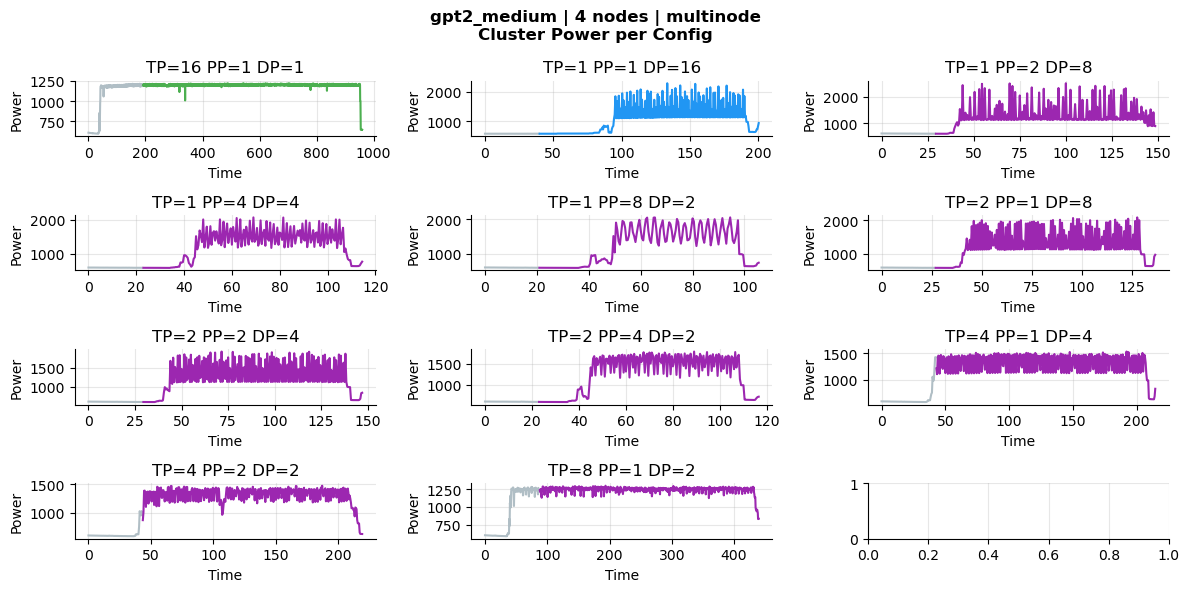

/ihome/stephenlee/wat29/.local/lib/python3.11/site-packages/dateutil/parser/_parser.py:1207: UnknownTimezoneWarning: tzname D identified but not understood.  Pass `tzinfos` argument in order to correctly return a timezone-aware datetime.  In a future version, this will raise an exception.
  warnings.warn("tzname {tzname} identified but not understood.  "


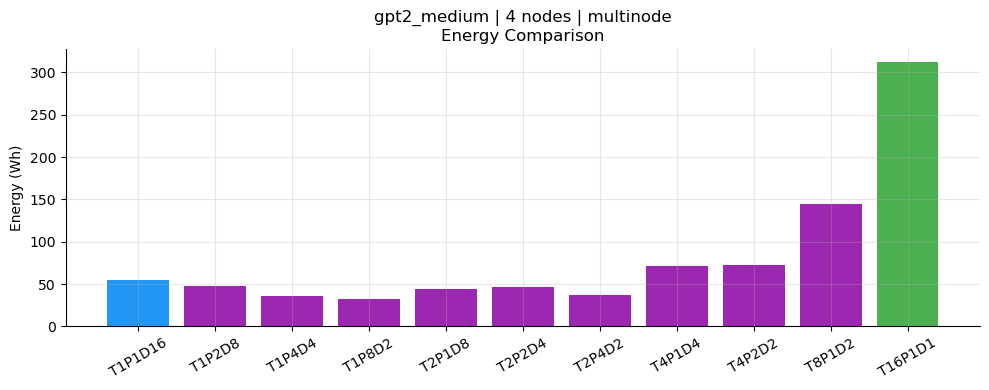


Saved everything to: /bgfs/stephenlee/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2_medium_n4_multinode


In [1]:
# Multi-node parallel-config power visualization
# ------------------------------------------------

import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ─── Style ───────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3",
    "tp": "#4CAF50",
    "pp": "#FF9800",
    "mixed": "#9C27B0",
}

# ─── Configuration ───────────────────────────────────────────
BASE = os.getcwd()

# CHANGE THIS
SWEEP_DIR = "power_logs/gpt2_medium_n4_1730306/"

# ─── Parse metadata from sweep dir ───────────────────────────
sweep_name = os.path.basename(os.path.normpath(SWEEP_DIR))

META_RE = re.compile(r"(?P<model>.+?)_n(?P<nodes>\d+)_\d+")
m = META_RE.match(sweep_name)

if m:
    model_name = m.group("model")
    num_nodes = int(m.group("nodes"))
else:
    model_name = sweep_name.split("-")[0]
    num_nodes = "unknown"

run_tag = f"{model_name}_n{num_nodes}_multinode"

PLOTS_DIR = os.path.join(BASE, "plots", run_tag)
INTERVAL_SECONDS = 0.5

os.makedirs(PLOTS_DIR, exist_ok=True)

print(f"Reading sweep:  {SWEEP_DIR}")
print(f"Model:          {model_name}")
print(f"Nodes:          {num_nodes}")
print(f"Mode:           multinode")
print(f"Saving plots:   {PLOTS_DIR}")

# ─── Helpers ─────────────────────────────────────────────────
CFG_RE = re.compile(r"tp(\d+)_pp(\d+)_dp(\d+)")

def parse_config_name(name):
    m = CFG_RE.match(name)
    if not m:
        return None
    tp, pp, dp = map(int, m.groups())
    return {"tp": tp, "pp": pp, "dp": dp, "name": name}

def classify(cfg):
    dims = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims >= 2: return "mixed"
    if cfg["tp"] > 1: return "tp"
    if cfg["pp"] > 1: return "pp"
    return "dp"

def load_config_dir(config_dir):
    rank_files = sorted(glob.glob(os.path.join(config_dir, "rank*.csv")))
    if not rank_files:
        return None

    rank_series = {}
    for f in rank_files:
        rank = int(re.search(r"rank(\d+)", os.path.basename(f)).group(1))
        df = pd.read_csv(f)
        if "total_power_W" not in df.columns or len(df) < 2:
            continue
        rank_series[rank] = df["total_power_W"].to_numpy()

    if not rank_series:
        return None

    n_min = min(len(v) for v in rank_series.values())
    for r in rank_series:
        rank_series[r] = rank_series[r][:n_min]

    cluster_total = np.sum(np.stack(list(rank_series.values())), axis=0)
    time_axis = np.arange(n_min) * INTERVAL_SECONDS

    return {
        "rank_power": rank_series,
        "cluster_power": cluster_total,
        "time": time_axis,
        "n_nodes": len(rank_series),
    }

# ─── Load configs ────────────────────────────────────────────
configs = {}
skipped = []

for d in sorted(os.listdir(SWEEP_DIR)):
    full = os.path.join(SWEEP_DIR, d)
    if not os.path.isdir(full):
        continue

    cfg = parse_config_name(d)
    if cfg is None:
        skipped.append(d)
        continue

    data = load_config_dir(full)
    if data is None:
        skipped.append(d)
        continue

    cfg.update(data)

    p = cfg["cluster_power"]
    warmup = int(len(p) * 0.2)
    steady = p[warmup:] if len(p) > warmup else p

    cfg["avg_power_w"] = float(p.mean())
    cfg["steady_avg_power_w"] = float(steady.mean())
    cfg["peak_power_w"] = float(p.max())
    cfg["duration_s"] = len(p) * INTERVAL_SECONDS
    cfg["energy_wh"] = float(p.sum()) * INTERVAL_SECONDS / 3600

    configs[d] = cfg

if skipped:
    print(f"Skipped: {', '.join(skipped)}")

if not configs:
    raise RuntimeError("No usable configs found")

# ─── Plot 1 ─────────────────────────────────────────────────
fig, axes = plt.subplots(len(configs)//3 + 1, 3, figsize=(12, 6))
axes = axes.flatten()

for ax, (name, cfg) in zip(axes, configs.items()):
    t = cfg["time"]
    p = cfg["cluster_power"]
    warmup = int(len(p) * 0.2)
    cls = classify(cfg)

    ax.plot(t[:warmup], p[:warmup], color="#B0BEC5")
    ax.plot(t[warmup:], p[warmup:], color=COLORS[cls])
    ax.set_title(f"TP={cfg['tp']} PP={cfg['pp']} DP={cfg['dp']}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Power")

fig.suptitle(
    f"{model_name} | {num_nodes} nodes | multinode\nCluster Power per Config",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "01_power.png"))
plt.show()

# ─── Plot 2 ─────────────────────────────────────────────────
sorted_cfgs = sorted(configs.values(), key=lambda c: (c["tp"], c["pp"], c["dp"]))

labels = [f"T{c['tp']}P{c['pp']}D{c['dp']}" for c in sorted_cfgs]
energy = [c["energy_wh"] for c in sorted_cfgs]

plt.figure(figsize=(10,4))
plt.bar(labels, energy, color=[COLORS[classify(c)] for c in sorted_cfgs])
plt.title(f"{model_name} | {num_nodes} nodes | multinode\nEnergy Comparison")
plt.xticks(rotation=30)
plt.ylabel("Energy (Wh)")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "02_energy.png"))
plt.show()

# ─── Summary ────────────────────────────────────────────────
summary = pd.DataFrame([{
    "Config": f"{c['tp']},{c['pp']},{c['dp']}",
    "Nodes": c["n_nodes"],
    "Energy": c["energy_wh"]
} for c in sorted_cfgs])

summary.to_csv(os.path.join(PLOTS_DIR, "summary.csv"), index=False)

print("\nSaved everything to:", PLOTS_DIR)